# STATE Codex r2 — 04 Secondary axes and mitochondrial controls

Run All invokes the source pipeline with `--force`: it recalculates the selected investigation from verified public inputs. Existing downloads can be reused after verification; derived result tables are not a substitute for the default calculation. The completed execution runs on exxact05. Use the documented Python environment and allow the source downloads, CPU time and disk space on a cold run.

The notebooks distinguish measured outcomes from investigations that originally stopped before scoring. For those stops, the reproduced objects are input levels, eligibility, resource diagnostics and the recorded decision; no performance curve is invented. Original results are comparison targets and historical evidence only. Reconstructed choices and numerical differences remain explicit.

See the [original report](../originals/REPORT.md), [candidate ledger](../originals/supporting/audit/candidate_axis_ledger.csv), [public sources](../methods/sources.json) and [pipeline](../methods/run_pipeline.py).

## 1. Data acquisition

A3 sampling support, A5 prospective dose displacement and A6 representation robustness depended on the unfinished A2e aggregation and were originally unscored. Their source input features and release assignments are rebuilt. A9 is a separate measured mitochondrial-burden investigation on released ST-SE scores and is reproduced below as such.

In [1]:
from pathlib import Path
import importlib.util,json,sys
import numpy as np
import pandas as pd
from IPython.display import display,JSON,Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'methods/replogle.py').is_file() and (p/'originals/REPORT.md').is_file())
spec=importlib.util.spec_from_file_location('state_codex_r2_notebook',ROOT/'notebooks/shared.py')
wf=importlib.util.module_from_spec(spec);spec.loader.exec_module(wf)
pd.set_option('display.max_colwidth',100);pd.set_option('display.max_rows',100)
manifest=wf.read_json(ROOT,'methods/sources.json')
sources=pd.DataFrame(manifest['inputs'])
display(sources[['path','bytes','sha256','url']])
if manifest.get('remote_observations'):
    display(Markdown('**Pinned observation-only source objects used for Replogle cell counts**'))
    display(pd.DataFrame(manifest['remote_observations']))
wf.source_functions(ROOT,'methods/acquire.py',['main'])
print('Manifest public input records:',len(sources))
print('The next cell executes actual source calculation for this investigation.')


,path,bytes,sha256,url
0,metadata/generalization.toml,150875,eac16fb06052dec9d6842dfae04d5ca693b847e3432f719a975adce205707783,https://raw.githubusercontent.com/ArcInstitute/state/da4178c930dc917dac6b56faf10a33e21bd8e905/st...
1,metadata/depmap_24q4_protein_coding_tpm_logp1.csv,506628654,2a71dc94110efcc0221eae821bb93a9f03b54bea16f005818911a09d33383d56,https://ndownloader.figshare.com/files/51065489
2,metadata/depmap_24q4_model.csv,645696,b7a0c1385e6cef30132b56aff61f1261d11e3f490490b355c430d32ee0dbdcfa,https://ndownloader.figshare.com/files/51065297
3,metadata/hpa_rna_celline.tsv.zip,205861141,e5b11779308c2720cfe89d9cb19932ad4c0c3fea0fa37e8c61a14d501995852a,https://www.proteinatlas.org/download/tsv/rna_celline.tsv.zip
4,ST-SE-Replogle/zeroshot/k562/eval_best.ckpt/k562_pred_de.csv,344243692,230ac1f1f8342d0c7f563166b6e8f9afeae6a02a62d0b737fda64168dde49ba0,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...
5,ST-SE-Replogle/zeroshot/k562/eval_best.ckpt/k562_real_de.csv,343530568,a367d89432c430f6bef3d3efd23c0a543144c1c55bb94e64c818c97de2cbd1dd,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...
6,ST-SE-Replogle/zeroshot/k562/eval_best.ckpt/k562_results.csv,528013,eaf22cc6169fa98ab90913366529db232ac2109fe421599f66d47b14ffd183b3,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...
7,ST-SE-Replogle/zeroshot/jurkat/eval_best.ckpt/jurkat_pred_de.csv,380905134,fd3422f18087eaf8357112bc0fd87faa8f95ed2a9ad95f0e7c4107d52754a9ca,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...
8,ST-SE-Replogle/zeroshot/jurkat/eval_best.ckpt/jurkat_real_de.csv,380988038,68fcb087841310e0e435b1bf63f1dbd69fc73c849d31a288f01d9d7ce40982ff,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...
9,ST-SE-Replogle/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv,568100,372db67f297565e5542cac1bda688586c07e03e92a999bea953a9df812ba5317,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...


**Pinned observation-only source objects used for Replogle cell counts**

,path,url,bytes,sha256,evidence
0,ST-SE-Replogle/zeroshot/k562/eval_best.ckpt/adata_real.h5ad,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...,3079506036,6951f4bffb532950c447e8dc300b2f42ab381c854273327f8cd38b84cfa4eb42,Pinned original release; observation-only range extraction
1,ST-SE-Replogle/zeroshot/jurkat/eval_best.ckpt/adata_real.h5ad,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...,3012265108,9df1a21e3b159fa3900a32dd8bd6b4d6dd8750838014d1d3997932d7cedc9673,Pinned original release; observation-only range extraction
2,ST-SE-Replogle/zeroshot/hepg2/eval_best.ckpt/adata_real.h5ad,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...,1577727376,75f79feff37c4334559ea88c1e2a27acd306eb7dee5a2e25f37c4860014ca2b9,Pinned original release; observation-only range extraction
3,ST-SE-Replogle/zeroshot/rpe1/eval_best.ckpt/adata_real.h5ad,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...,2837025870,f3363768db24b7eee9cb55507443366f8e15b6f9e5731ac415f533b757a5b5b1,Pinned original release; observation-only range extraction


**Executed implementation:** `methods/acquire.py::main`

def main():
    ap=argparse.ArgumentParser();ap.add_argument('--root',type=Path,required=True);ap.add_argument('--reuse',type=Path);ap.add_argument('--manifest-only',action='store_true');ap.add_argument('--refresh-manifest',action='store_true');a=ap.parse_args();r=a.root.resolve()
    p=r/'methods/sources.json';m=json.loads(p.read_text()) if p.exists() and not a.refresh_manifest else manifest(r)
    if a.manifest_only:return
    reuse={}
    if a.reuse:
        for x in json.loads((a.reuse/'methods/sources.json').read_text())['inputs']:reuse[x['sha256']]=a.reuse/'inputs'/x['path']
    def one(x):
        p=r/'inputs'/x['path'];p.parent.mkdir(parents=True,exist_ok=True)
        if p.exists() and p.stat().st_size==x['bytes'] and sha(p)==x['sha256']:return {**x,'verified':True,'route':'existing'}
        q=reuse.get(x['sha256'])
        if q and q.exists() and q.stat().st_size==x['bytes'] and sha(q)==x['sha256']:
            p.symlink_to(q.resolve());print('REUSE',x['path'],flush=True);return {**x,'verified':True,'route':'identical_sha256_symlink'}
        tmp=p.with_name(p.name+'.part')
        for attempt in range(4):
            try:
                with urllib.request.urlopen(x['url'],timeout=180) as src,tmp.open('wb') as dst:
                    for b in iter(lambda:src.read(8*1024*1024),b''):dst.write(b)
                assert tmp.stat().st_size==x['bytes'],(tmp.stat().st_size,x['bytes'])
                assert sha(tmp)==x['sha256'],'Source checksum mismatch'
                os.replace(tmp,p);print('VERIFIED',x['path'],x['bytes'],flush=True)
                return {**x,'verified':True,'route':'public_download'}
            except Exception:
                if attempt==3:raise
                time.sleep(2*(attempt+1))
    with concurrent.futures.ThreadPoolExecutor(max_workers=2) as pool:done=list(pool.map(one,m['inputs']))
    (r/'inputs/DOWNLOAD_RECEIPT.json').write_text(json.dumps(dict(source_manifest_sha256=sha(r/'methods/sources.json'),inputs=done),indent=2)+'\n')

Manifest public input records: 49
The next cell executes actual source calculation for this investigation.


## 2. Processing

Aggregate real Tahoe observation metadata into condition-level support/QC features, rebuild the original cohort, derive secondary input levels and evaluate A9 from actual released scores. The original metadata aggregation helper is missing; the explicit reconstruction is reported and may change adjusted or mitochondrial results.

In [2]:
pipeline=wf.run_pipeline(ROOT,'secondary')
wf.source_functions(ROOT,'methods/tahoe.py',['controls'])
wf.source_functions(ROOT,'methods/closures.py',['run'])
secondary=wf.read_csv(ROOT,'computed/closures/secondary_input_axes.csv')
display(secondary.head(12));wf.source_receipts(ROOT,['tahoe_controls','tahoe_analysis','closures'])


Calculating the original source workflow for secondary ; source files are verified before reuse.


Calculating from source inputs: tahoe_analysis


TAHOE A8


TAHOE A10


TAHOE A9


Calculating from source inputs: closures


... (8 outputs left out)

**Calculated stage:** tahoe_analysis

<IPython.core.display.JSON object>

**Calculated stage:** closures

<IPython.core.display.JSON object>

## 3. Axis

Secondary sampling weakness is negative log1p treated-cell count; dose levels and release/representation assignments are explicit source attributes. These input values are not treated as previously observed secondary performance findings. A9 uses measured condition mitochondrial fraction with its own original contract.

In [3]:
display(wf.read_csv(ROOT,'computed/closures/release_modality_assignments.csv'))
display(JSON(wf.read_json(ROOT,'originals/supporting/audit/axis/frozen_axis_secondary.json')))
display(JSON(wf.read_json(ROOT,'originals/supporting/audit/axis/frozen_axis_A9_mito.json')))


,dataset,modality,model,representation,setting,context,source_path,source_sha256
0,Replogle,genetic CRISPRi,ST-SE-Replogle,SE,zeroshot,k562,ST-SE-Replogle/zeroshot/k562/eval_best.ckpt/k562_results.csv,eaf22cc6169fa98ab90913366529db232ac2109fe421599f66d47b14ffd183b3
1,Replogle,genetic CRISPRi,ST-SE-Replogle,SE,zeroshot,jurkat,ST-SE-Replogle/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv,372db67f297565e5542cac1bda688586c07e03e92a999bea953a9df812ba5317
2,Replogle,genetic CRISPRi,ST-SE-Replogle,SE,zeroshot,hepg2,ST-SE-Replogle/zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv,9b7b329faa11cfdfbbac37ad571bdf47e8af7f988d61561eab51d80dce9d643a
3,Replogle,genetic CRISPRi,ST-SE-Replogle,SE,zeroshot,rpe1,ST-SE-Replogle/zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv,ce7034b9e7af7255f44347ac9fdcbdd41e13b8ce674cab3c2700c0b41a1b1ffa
4,Replogle,genetic CRISPRi,ST-HVG-Replogle,HVG,zeroshot,k562,ST-HVG-Replogle/zeroshot/k562/eval_best.ckpt/k562_results.csv,8bd145c4667e03c9e367079dcfb38126e4e1f06b562f8a3fa6d1eaa1d0ba5821
5,Replogle,genetic CRISPRi,ST-HVG-Replogle,HVG,zeroshot,jurkat,ST-HVG-Replogle/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv,3efc817549bbf24edd6e427fb99466f58de8fadb3a4b4335523f5cfac1bc8098
6,Replogle,genetic CRISPRi,ST-HVG-Replogle,HVG,zeroshot,hepg2,ST-HVG-Replogle/zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv,0c930ad038b56c6f43d25896a15cd68e121d8902e5457718b4dfc9f163f10604
7,Replogle,genetic CRISPRi,ST-HVG-Replogle,HVG,zeroshot,rpe1,ST-HVG-Replogle/zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv,c187b3a026c8381a84acbe5035efa30947a6774c82a6519749b1b37e85fdd14d
8,Tahoe,chemical drug,ST-SE-Tahoe,SE,fewshot,C32,ST-SE-Tahoe/fewshot/state_generalization_X_state/eval_best.ckpt/C32_results.csv,9fee724f7d5dc46a3e0061e264347ce4c8c5c29b6c0dac2dc67303bcae25894a
9,Tahoe,chemical drug,ST-SE-Tahoe,SE,fewshot,HOP62,ST-SE-Tahoe/fewshot/state_generalization_X_state/eval_best.ckpt/HOP62_results.csv,646052bbdb9844e1a2b94f19c095d0f5a07db9529010f41252c61ba228544d56


<IPython.core.display.JSON object>

<IPython.core.display.JSON object>

## 4. Levels and eligibility

Show actual support-level ranges, three dose levels and source representation coverage. A9’s stable five-level ordering is reconstructed from its measured condition feature. The level rules and unknown historical aggregation details remain visible.

In [4]:
display(wf.read_csv(ROOT,'computed/closures/support_levels.csv'))
display(secondary[['dose','dose_level']].drop_duplicates().sort_values('dose_level'))
a9=wf.read_csv(ROOT,'computed/tahoe/A9_units.csv')
display(a9.groupby('mito_level').agg(units=('drug','size'),minimum=('mito','min'),maximum=('mito','max')))


,support_level,units,mean_treated,min_treated,max_treated
0,1.0,597,4847.802345,3319.0,14192.0
1,2.0,597,2650.438861,2154.0,3318.0
2,3.0,597,1772.075377,1457.0,2154.0
3,4.0,597,1150.147404,881.0,1455.0
4,5.0,596,578.016779,1.0,881.0


,dose,dose_level
2,5.00,1
1,0.50,2
0,0.05,3


,units,minimum,maximum
mito_level,,,
1.0,597,0.010210,0.044044
2.0,597,0.044049,0.054815
3.0,597,0.054860,0.068728
4.0,597,0.068734,0.087925
5.0,596,0.088031,0.166372


## 5. Model / released scores

A3/A5/A6 have no original outcome test and no performance result is substituted for them. A9 does have released individual measurements; their raw/adjusted fits use the declared count/QC reconstruction and preserve checkpoint identity.

In [5]:
closures=wf.read_json(ROOT,'computed/closures/closure_diagnostics.json')
for name in ['A3','A5','A6']:display(JSON({name:closures[name]}))
display(a9[['context','drug','dose','mito','mito_level','score','n_de','n_treated','n_control','gene_mean','umi_mean']].head(12))


<IPython.core.display.JSON object>

<IPython.core.display.JSON object>

<IPython.core.display.JSON object>

,context,drug,dose,mito,mito_level,score,n_de,n_treated,n_control,gene_mean,umi_mean
0,C32,(R)-Verapamil (hydrochloride),0.05,0.054788,2.0,0.566095,320.0,2180.0,4178.0,1162.405046,1768.183486
1,C32,(R)-Verapamil (hydrochloride),0.50,0.048386,2.0,0.464402,427.0,1233.0,5082.0,911.892944,1277.640714
2,C32,(R)-Verapamil (hydrochloride),5.00,0.056329,3.0,0.571556,531.0,4124.0,8290.0,1340.717992,2152.836566
3,C32,(S)-Crizotinib,0.05,0.046369,2.0,0.105998,526.0,1974.0,1662.0,1010.403242,1492.146910
4,C32,(S)-Crizotinib,0.50,0.040158,1.0,-0.064558,220.0,1445.0,3763.0,1062.401384,1558.880277
5,C32,(S)-Crizotinib,5.00,0.065876,3.0,0.009882,283.0,1015.0,2165.0,1109.730049,1704.568473
6,C32,8-Hydroxyquinoline,0.05,0.018902,1.0,0.591875,289.0,1657.0,4178.0,1171.115269,1731.705492
7,C32,8-Hydroxyquinoline,0.50,0.015923,1.0,0.545590,359.0,1595.0,5082.0,994.996865,1373.663950
8,C32,8-Hydroxyquinoline,5.00,0.016338,1.0,0.583265,617.0,3863.0,8290.0,1289.959617,1944.671240
9,C32,APTO-253,0.05,0.060332,3.0,0.581226,756.0,1521.0,4343.0,1427.744247,2274.554898


## 6. Curves, controls and diagnostics

A9’s curve, drug-block fits and original-result comparison are calculated from actual rows. Its reconstructed metadata aggregation can shift the raw/adjusted values; the discrepancy remains explicit. For the unscored secondary candidates, the input/dependency tables above are the diagnostic result.

**Executed implementation:** `methods/common.py::fisher`

def fisher(x):return np.arctanh(np.clip(np.asarray(x,float),-1+1e-7,1-1e-7))

**Executed implementation:** `methods/common.py::cluster_fit`

def cluster_fit(d,y,x,cluster,adjust=(),fixed=(),cluster_fixed=False,draws=10000,seed=20260715):
    """OLS and paired cluster-resampling percentile CI via exact sufficient stats.

    When cluster_fixed=True, first remove the cluster mean. Resampling duplicated
    clusters is equivalent to giving that cluster an integer frequency weight.
    Axis standardization is fixed on the original analyzed rows, not redefined
    within each bootstrap draw. No historical estimates enter this function.
    """
    cols=[y,x,cluster,*adjust,*fixed];d=d.dropna(subset=cols).copy()
    X=[np.ones(len(d)),zscore(d[x])];names=['intercept',x]
    for c in adjust:
        v=np.asarray(d[c],float)
        if np.std(v)>0:X.append(zscore(v));names.append(c)
    for c in fixed:
        for val in sorted(d[c].unique())[1:]:X.append((d[c]==val).astype(float).values);names.append(f'{c}={val}')
    X=np.column_stack(X);Y=d[y].to_numpy(float)
    groups=sorted(d[cluster].unique());codes=pd.Categorical(d[cluster],categories=groups).codes
    if cluster_fixed:
        for j in range(len(groups)):
            sel=codes==j;X[sel]-=X[sel].mean(axis=0);Y[sel]-=Y[sel].mean()
        X=X[:,1:];names=names[1:];axis_idx=0
    else:axis_idx=1
    gxx=np.zeros((len(groups),X.shape[1],X.shape[1]));gxy=np.zeros((len(groups),X.shape[1]))
    for j in range(len(groups)):
        sel=codes==j;gxx[j]=X[sel].T@X[sel];gxy[j]=X[sel].T@Y[sel]
    coefficient=np.linalg.lstsq(X,Y,rcond=None)[0];rng=np.random.default_rng(seed);boot=[]
    for start in range(0,draws,100):
        n=min(100,draws-start);w=rng.multinomial(len(groups),np.full(len(groups),1/len(groups)),size=n)
        xx=np.einsum('bg,gij->bij',w,gxx);xy=w@gxy
        for a,b in zip(xx,xy):boot.append(np.linalg.lstsq(a,b,rcond=None)[0][axis_idx])
    return dict(n=len(d),clusters=len(groups),coefficient=float(coefficient[axis_idx]),ci95=np.quantile(boot,[.025,.975]).tolist(),draws=draws,seed=seed,design_columns=names,cluster_fixed_effect=cluster_fixed,axis_standardization='population SD on all analyzed rows',coefficients=dict(zip(names,coefficient))),np.asarray(boot)

**Executed implementation:** `methods/common.py::curve`

def curve(d,level,score,cluster,draws=10000,seed=20260715):
    groups=sorted(d[cluster].unique());levels=sorted(d[level].unique());rng=np.random.default_rng(seed)
    w=rng.multinomial(len(groups),np.full(len(groups),1/len(groups)),size=draws);rows=[];boot={}
    for v in levels:
        q=d[d[level]==v];g=q.groupby(cluster)[score].agg(['sum','count']).reindex(groups,fill_value=0)
        b=(w@g['sum'].values)/(w@g['count'].values);boot[str(v)]=b
        rows.append(dict(level=v,n=len(q),clusters=q[cluster].nunique(),mean=q[score].mean(),ci_low=np.quantile(b,.025),ci_high=np.quantile(b,.975)))
    return pd.DataFrame(rows),boot

,fit,n,clusters,coefficient,ci95,draws,seed,design_columns,cluster_fixed_effect,axis_standardization
0,raw,2984,199,0.025264,"[0.014108452047912425, 0.03619252941189629]",10000,20260716,[mito],True,population SD on all analyzed rows
1,adjusted,2984,199,0.017824,"[-0.01723335196083973, 0.049995691569679306]",10000,20260716,"[mito, log_n_de, log_n_treated, log_n_control, log_gene_mean, log_umi_mean, context=HOP62, conte...",True,population SD on all analyzed rows


,level,n,clusters,mean,ci_low,ci_high
0,1.0,597,135,0.458138,0.425284,0.489177
1,2.0,597,182,0.459898,0.434811,0.485015
2,3.0,597,188,0.455814,0.431081,0.479741
3,4.0,597,190,0.464766,0.437508,0.491079
4,5.0,596,168,0.470075,0.430548,0.507691


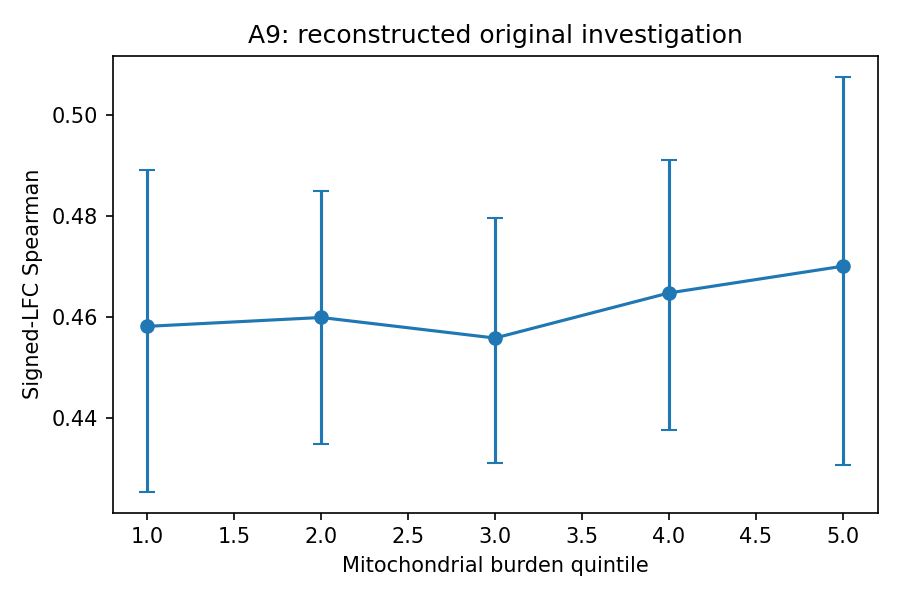

,analysis,metric,historical,reconstructed,difference
2,A9,raw_slope,-0.000442,0.025264,0.025706


In [6]:
wf.source_functions(ROOT,'methods/common.py',['fisher','cluster_fit','curve'])
result=wf.read_json(ROOT,'computed/tahoe/A9_summary.json')
wf.show_fits(result);display(wf.read_csv(ROOT,'computed/tahoe/A9_curve.csv'))
wf.show_curve(ROOT,'A9_curve.png')
comparison=wf.read_json(ROOT,'computed/tahoe/historical_comparison.json')
display(pd.DataFrame(comparison).query("analysis == 'A9'"))


## 7. Historical result and decision

The original agent closed A3/A5/A6 as untested dependency gaps and rejected the checkpoint-specific A9 signal after confirmation. This preserves those historical determinations while showing the newly reconstructed inputs and A9 result, including disagreements.

In [7]:
wf.original_rows(ROOT,['A3','A5','A6','A9'])
print('No A3/A5/A6 outcome curve is created; those tests were not performed in the original investigation.')


,candidate_id,axis,status,decision_reason,next_action
4,A3,cell count / sampling depth,resource_gap,specified prospectively but depended on the unfinished Tahoe feature/reference aggregation; no t...,closed untested; requires completed Tahoe condition aggregate
6,A5,dose-time displacement,resource_gap,dose axis was specified prospectively but same-example reference and controls depended on the un...,closed untested; requires completed Tahoe condition aggregate
7,A6,representation family,resource_gap,paired sensitivity was specified but its prospective stratification depended on the unfinished T...,closed untested; official score metric alone is not the frozen all-feature test
10,A9,treated-cell mitochondrial fraction,negative,"unread zero-shot confirmation slope -0.00044 CI [-0.03020,0.02835], adjusted +0.02508; endpoint ...",reject checkpoint-specific discovery


These are attributed original decisions, not new adjudications.
No A3/A5/A6 outcome curve is created; those tests were not performed in the original investigation.
